# Импорты и настройки.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)
sns.set_theme(style="whitegrid")

None

# Загрузка данных.

In [2]:
df = pd.read_csv("bank-additional-full.csv", sep=";")
df.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,261,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,149,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,226,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,151,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,307,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


В таблице одна строка описывает один контакт в рамках кампании. Столбец `y` содержит результат: оформил клиент вклад (`yes`) или нет (`no`). Остальные столбцы описывают клиента, способ и историю контактов, а также экономические условия.

# Размер, типы, пропуски.

In [3]:
print("Размер:", df.shape)
df.info()

Размер: (41188, 21)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  object 
 2   marital         41188 non-null  object 
 3   education       41188 non-null  object 
 4   default         41188 non-null  object 
 5   housing         41188 non-null  object 
 6   loan            41188 non-null  object 
 7   contact         41188 non-null  object 
 8   month           41188 non-null  object 
 9   day_of_week     41188 non-null  object 
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  object 
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.i

None

Набор данных содержит 41188 наблюдений по 21 признаку. В данных выделяется 11 категориальных, 5 целочисленных и 5 вещественночисленных признаков.

# Статистика по числовым и категориальным признакам.

In [4]:
display(df.describe().T)
display(df.describe(include="object").T)

,count,mean,std,min,25%,50%,75%,max
age,41188.0,40.024060,10.421250,17.000,32.000,38.000,47.000,98.000
duration,41188.0,258.285010,259.279249,0.000,102.000,180.000,319.000,4918.000
campaign,41188.0,2.567593,2.770014,1.000,1.000,2.000,3.000,56.000
pdays,41188.0,962.475454,186.910907,0.000,999.000,999.000,999.000,999.000
previous,41188.0,0.172963,0.494901,0.000,0.000,0.000,0.000,7.000
emp.var.rate,41188.0,0.081886,1.570960,-3.400,-1.800,1.100,1.400,1.400
cons.price.idx,41188.0,93.575664,0.578840,92.201,93.075,93.749,93.994,94.767
cons.conf.idx,41188.0,-40.502600,4.628198,-50.800,-42.700,-41.800,-36.400,-26.900
euribor3m,41188.0,3.621291,1.734447,0.634,1.344,4.857,4.961,5.045
nr.employed,41188.0,5167.035911,72.251528,4963.600,5099.100,5191.000,5228.100,5228.100


,count,unique,top,freq
job,41188,12,admin.,10422
marital,41188,4,married,24928
education,41188,8,university.degree,12168
default,41188,3,no,32588
housing,41188,3,yes,21576
loan,41188,3,no,33950
contact,41188,2,cellular,26144
month,41188,10,may,13769
day_of_week,41188,5,thu,8623
poutcome,41188,3,nonexistent,35563


None

В таблицах выше приведены описательные статистики: для числовых признаков — количество, среднее, разброс и границы значений; для категориальных — число записей и наиболее частые категории. Наиболее частая профессия — `admin.`, большинство клиентов состоят в браке, а для связи чаще использовался канал `cellular`.

# Пропуски и дубликаты в данных.

In [5]:
print("Количество явных пропусков:", int(df.isna().sum().sum()))
print("Количество полных дубликатов:", int(df.duplicated().sum()))

Количество явных пропусков: 0
Количество полных дубликатов: 12


None

In [6]:
dups = df[df.duplicated(keep=False)].sort_values(by=list(df.columns))
print("Строк, входящих в полные дубликаты:", len(dups))
display(dups)

Строк, входящих в полные дубликаты: 24


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
28476,24,services,single,high.school,no,yes,no,cellular,apr,tue,114,1,999,0,nonexistent,-1.8,93.075,-47.1,1.423,5099.1,no
28477,24,services,single,high.school,no,yes,no,cellular,apr,tue,114,1,999,0,nonexistent,-1.8,93.075,-47.1,1.423,5099.1,no
14155,27,technician,single,professional.course,no,no,no,cellular,jul,mon,331,2,999,0,nonexistent,1.4,93.918,-42.7,4.962,5228.1,no
14234,27,technician,single,professional.course,no,no,no,cellular,jul,mon,331,2,999,0,nonexistent,1.4,93.918,-42.7,4.962,5228.1,no
18464,32,technician,single,professional.course,no,yes,no,cellular,jul,thu,128,1,999,0,nonexistent,1.4,93.918,-42.7,4.968,5228.1,no
18465,32,technician,single,professional.course,no,yes,no,cellular,jul,thu,128,1,999,0,nonexistent,1.4,93.918,-42.7,4.968,5228.1,no
32505,35,admin.,married,university.degree,no,yes,no,cellular,may,fri,348,4,999,0,nonexistent,-1.8,92.893,-46.2,1.313,5099.1,no
32516,35,admin.,married,university.degree,no,yes,no,cellular,may,fri,348,4,999,0,nonexistent,-1.8,92.893,-46.2,1.313,5099.1,no
12260,36,retired,married,unknown,no,no,no,telephone,jul,thu,88,1,999,0,nonexistent,1.4,93.918,-42.7,4.966,5228.1,no
12261,36,retired,married,unknown,no,no,no,telephone,jul,thu,88,1,999,0,nonexistent,1.4,93.918,-42.7,4.966,5228.1,no


None

Явных пропусков (`NaN`) в таблице нет. Найдены 12 полных дубликатов — строк, совпадающих по всем столбцам.

In [7]:
df_clean = df.drop_duplicates().reset_index(drop=True)
print("Размер до удаления дубликатов:", df.shape)
print("Размер после удаления дубликатов:", df_clean.shape)
df = df_clean.copy()

Размер до удаления дубликатов: (41188, 21)
Размер после удаления дубликатов: (41176, 21)


12 полных дубликатов удалены, потому что совпадают по всем полям, включая длительность разговора. В датасете нет идентификатора клиента, поэтому нельзя установить причину появления совпадений. Для дальнейшего анализа и разделения на обучение и проверку используем `df` после удаления дублей: это снижает риск того, что одинаковая запись попадёт в обе выборки. Удалено 0,03% строк.

# Баланс/дисбаланс классов.

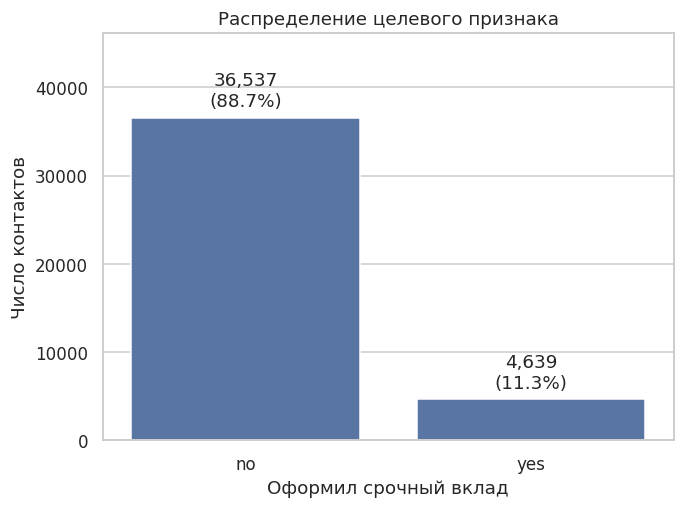

None

In [8]:
ax = sns.countplot(data=df, x="y", order=["no", "yes"])
total = len(df)
for patch in ax.patches:
    count = int(patch.get_height())
    percentage = f"{100 * count / total:.1f}%"
    ax.annotate(
        f"{count:,}\n({percentage})",
        (patch.get_x() + patch.get_width() / 2, patch.get_height()),
        ha="center", va="bottom", xytext=(0, 5), textcoords="offset points"
    )
ax.set_title("Распределение целевого признака")
ax.set_xlabel("Оформил срочный вклад")
ax.set_ylabel("Число контактов")
ax.set_ylim(0, total * 1.12)
plt.tight_layout()
plt.show()

После удаления полных дубликатов осталось 41 176 строк: 36 537 ответов `no` (88,7%) и 4 639 ответов `yes` (11,3%). Класс `yes` встречается примерно в 8 раз реже. Поэтому при оценке модели одной accuracy будет недостаточно: важно отдельно смотреть, сколько клиентов с реальным откликом модель нашла и сколько её прогнозов `yes` оказались верными.

# Подготовка к анализу данных.

In [9]:
base_rate = df["y"].eq("yes").mean()
df["is_yes"] = df["y"].eq("yes").astype(int)
month_order = ["mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"]
df["month"] = pd.Categorical(df["month"], categories=month_order, ordered=True)
print(f"Доля ответов yes после удаления дубликатов: {base_rate:.3%}")

Доля ответов yes после удаления дубликатов: 11.266%


None

Для расчётов результат `y` переведён в числовой признак: `yes` — 1, `no` — 0. Поэтому среднее значение `is_yes` равно доле отклика. Месяц задан в календарном порядке, чтобы таблицы и графики не сортировали его по алфавиту.

# Анализ истории контактов.

## Обнаружение неявного пропуска в данных о количестве дней, прошедших с момента последнего контакта банка с клиентом.

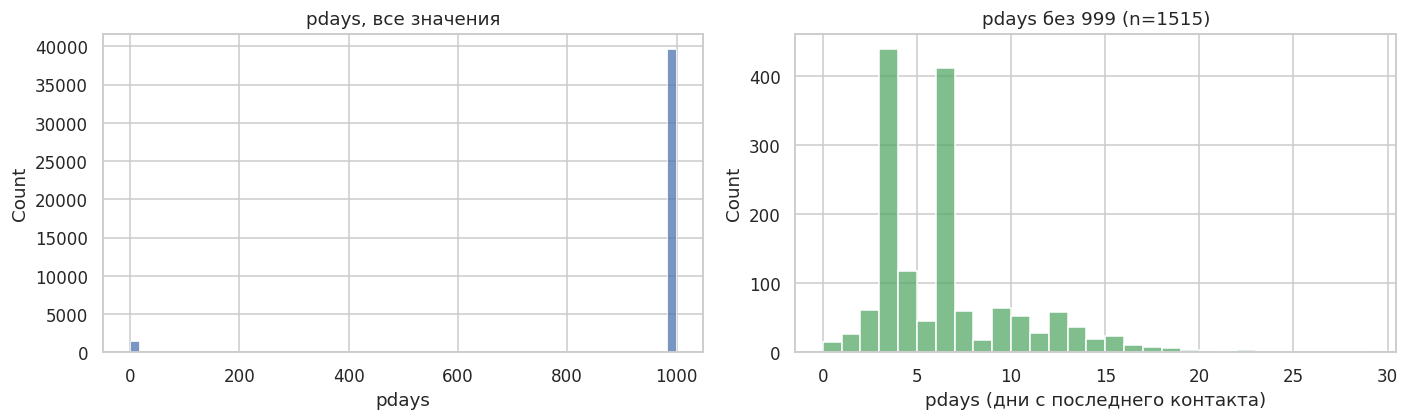

None

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# слева: всё как есть — 999 доминирует, реальные дни не видны
sns.histplot(df["pdays"], bins=60, ax=axes[0], color="C0")
axes[0].set_title("pdays, все значения")
axes[0].set_xlabel("pdays")

# справа: только те, где pdays != 999 — вот это и есть "настоящие" дни
real = df.loc[df["pdays"] != 999, "pdays"]
sns.histplot(real, bins=range(0, 30), ax=axes[1], color="C2")
axes[1].set_title(f"pdays без 999 (n={len(real)})")
axes[1].set_xlabel("pdays (дни с последнего контакта)")

plt.tight_layout(); plt.show()

Значение `pdays=999` — специальный код, а не 999 дней. Оно означает, что обычный срок после последнего контакта в этом поле не указан. Поэтому распределение реальных значений `pdays` нужно смотреть отдельно от кода 999.

## Обнаружение неявных пропусков в данных со значением unknown.

In [11]:
unknown_counts = (df == "unknown").sum()
unknown_counts = unknown_counts[unknown_counts > 0].sort_values(ascending=False)
unknown_table = pd.DataFrame({
    "Количество unknown": unknown_counts,
    "Доля строк, %": (unknown_counts / len(df) * 100).round(2),
})
display(unknown_table)

,Количество unknown,"Доля строк, %"
default,8596,20.88
education,1730,4.20
housing,990,2.40
loan,990,2.40
job,330,0.80
marital,80,0.19


None

Значение `unknown` встречается в шести категориальных признаках. Чаще всего оно указано для `default` — 8 596 строк (20,9%). Пока неизвестно, почему это значение отсутствует, поэтому в анализе и при подготовке категориальных признаков для модели его следует оставить отдельной категорией, а не заменять на `no` или удалять строки без обоснования.

## Обработка данных о количестве дней, прошедших с момента последнего контакта банка с клиентом.

In [12]:
df["pdays_is_recorded"] = (df["pdays"] != 999).astype(int)
df["pdays_clean"] = df["pdays"].where(df["pdays"] != 999)
print("Контакты с pdays=999:", int(df["pdays"].eq(999).sum()))
print("Контакты с известным числом дней:", int(df["pdays"].ne(999).sum()))

Контакты с pdays=999: 39661
Контакты с известным числом дней: 1515


None

В `pdays` код 999 заменён на пропуск только в отдельной копии `pdays_clean`, чтобы его не воспринимать как реальное количество дней. Отдельный признак `pdays_is_recorded` показывает, заполнено ли поле обычным числом дней. Перед объединением `pdays` с другими признаками истории контактов дополнительно проверена их согласованность.

In [13]:
history_consistency = pd.crosstab(
    df["pdays"].eq(999).map({True: "pdays=999", False: "pdays≠999"}),
    df["previous"].gt(0).map({True: "previous>0", False: "previous=0"}),
    margins=True,
)
print("Сопоставление признаков истории контактов")
display(history_consistency)
print("\nРезультат предыдущей кампании в тех же группах")
display(pd.crosstab(
    df["pdays"].eq(999).map({True: "pdays=999", False: "pdays≠999"}),
    df["poutcome"],
    margins=True,
))

Сопоставление признаков истории контактов

Результат предыдущей кампании в тех же группах


previous,previous=0,previous>0,All
pdays,,,
pdays=999,35551,4110,39661
pdays≠999,0,1515,1515
All,35551,5625,41176


poutcome,failure,nonexistent,success,All
pdays,,,,
pdays=999,4110,35551,0,39661
pdays≠999,142,0,1373,1515
All,4252,35551,1373,41176


None

В 4 110 строках одновременно указаны `pdays=999` и `previous>0`; у них `poutcome=nonexistent`. Эти поля истории контактов не полностью согласуются между собой. Поэтому в анализе и модели их лучше пока не объединять в один признак: сохраняем поля раздельно и отдельно проверяем качество модели с каждым из них.

# Визуализации анализируемых данных.

In [14]:
df["pdays_bin"] = pd.cut(
    df["pdays_clean"],
    bins=[-1, 0, 3, 7, 14, 30],
    labels=["0 дней", "1–3 дня", "4–7 дней", "8–14 дней", "15–30 дней"],
    include_lowest=True,
)
df["age_group"] = pd.cut(
    df["age"],
    bins=[0, 25, 35, 45, 55, 65, 120],
    labels=["до 25", "26–35", "36–45", "46–55", "56–65", "66+"],
    include_lowest=True,
)

Возраст разбит на интервалы примерно по 10 лет, а крайние группы выделены отдельно, чтобы сравнение было понятным. Для `pdays` выбраны более короткие интервалы в начале шкалы (0, 1–3, 4–7, 8–14, 15–30 дней), поскольку важно сравнить недавние контакты. Значение 999 в эти интервалы не включено.

## Анализ истории контактов.

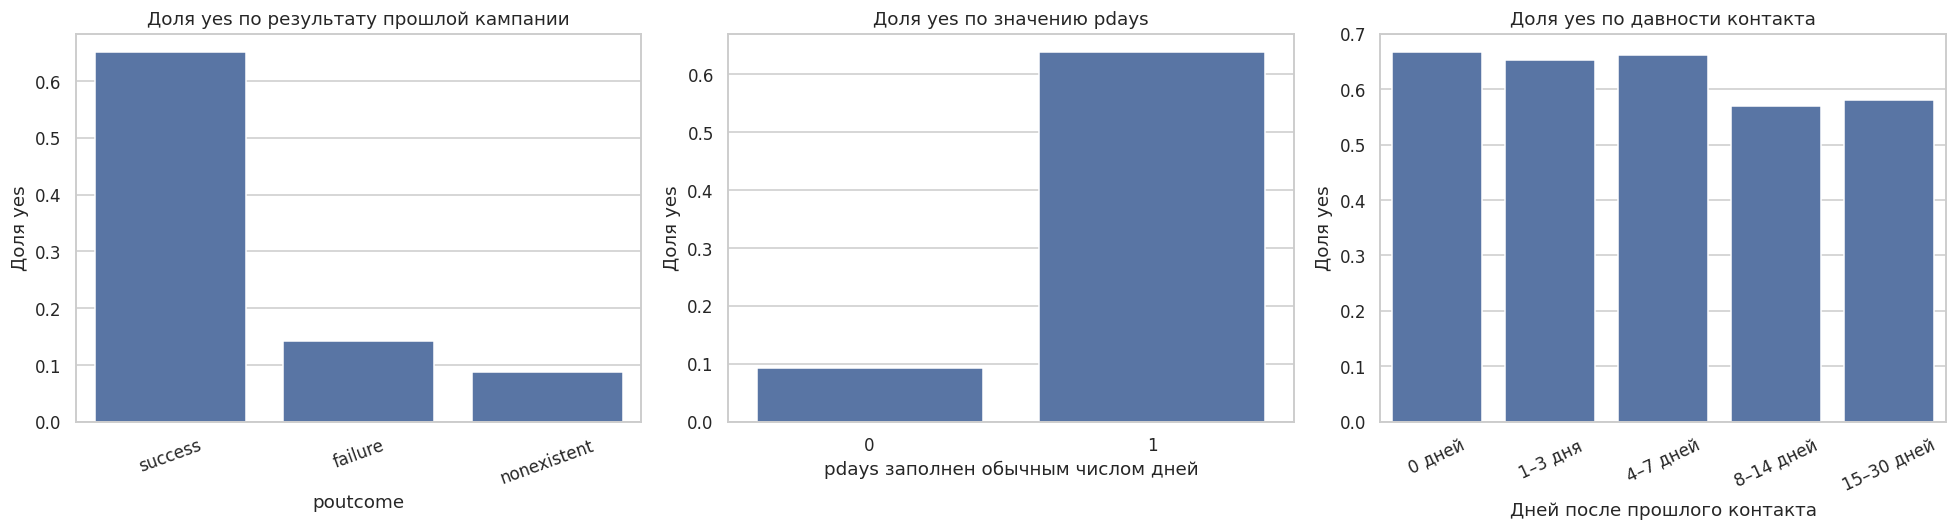

None

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.barplot(
    data=df, x="poutcome", y="is_yes",
    order=df.groupby("poutcome")["is_yes"].mean().sort_values(ascending=False).index,
    ax=axes[0], errorbar=None
)
axes[0].set_title("Доля yes по результату прошлой кампании")
axes[0].set_ylabel("Доля yes")
axes[0].tick_params(axis="x", rotation=20)

sns.barplot(data=df, x="pdays_is_recorded", y="is_yes", ax=axes[1], errorbar=None)
axes[1].set_title("Доля yes по значению pdays")
axes[1].set_xlabel("pdays заполнен обычным числом дней")
axes[1].set_ylabel("Доля yes")

sns.barplot(data=df, x="pdays_bin", y="is_yes", ax=axes[2], errorbar=None)
axes[2].set_title("Доля yes по давности контакта")
axes[2].set_xlabel("Дней после прошлого контакта")
axes[2].set_ylabel("Доля yes")
axes[2].tick_params(axis="x", rotation=25)

plt.tight_layout()
plt.show()

По результату прошлой кампании доля `yes` составила 65,1% после `success`, 14,2% после `failure` и 8,8% при `nonexistent`. Среди строк с обычным значением `pdays` доля `yes` — 63,8%; при `pdays=999` — 8,8%. Это заметные связи в данных, но они не доказывают, что прошлый контакт стал причиной текущего отклика. Значение 999 и число прошлых контактов дополнительно проверены на согласованность.

Возраст: минимум и максимум 17 и 98


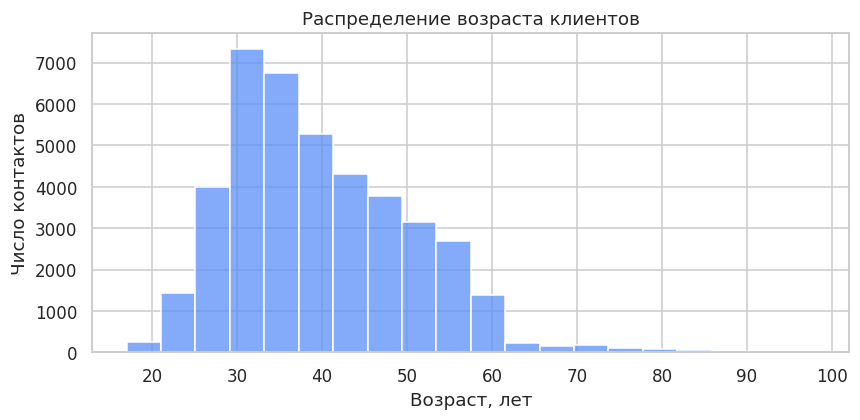

None

In [16]:
# Распределение возраста и проверка крайних значений
print("Возраст: минимум и максимум", int(df["age"].min()), "и", int(df["age"].max()))
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(df["age"], bins=20, color="#5B8FF9", ax=ax)
ax.set_title("Распределение возраста клиентов")
ax.set_xlabel("Возраст, лет")
ax.set_ylabel("Число контактов")
plt.tight_layout()
plt.show()

Возраст в таблице лежит в диапазоне от 17 до 98 лет. Гистограмма показывает распределение клиентов по возрасту. По одному крайнему значению нельзя автоматически считать запись ошибочной, поэтому возраст не удаляли.

In [17]:
# Число контактов с клиентом в рамках текущей кампании
campaign_groups = pd.cut(
    df["campaign"],
    bins=[0, 1, 2, 3, 5, 10, float("inf")],
    labels=["1", "2", "3", "4–5", "6–10", "11+"],
)
campaign_summary = df.assign(campaign_group=campaign_groups).groupby("campaign_group", observed=False)["is_yes"].agg(
    contacts="size", deposits="sum", response_rate="mean"
)
campaign_summary["response_rate_pct"] = (campaign_summary["response_rate"] * 100).round(1)
display(campaign_summary[["contacts", "deposits", "response_rate_pct"]].rename(columns={
    "contacts": "Контакты", "deposits": "Оформили вклад", "response_rate_pct": "Отклик, %"
}))

,Контакты,Оформили вклад,"Отклик, %"
campaign_group,,,
1,17634,2299,13.0
2,10568,1211,11.5
3,5340,574,10.7
4–5,4249,369,8.7
6–10,2516,159,6.3
11+,869,27,3.1


None

В таблице доля отклика в целом снижается при большем числе контактов в рамках кампании. Это наблюдение не означает, что после определённого звонка нужно прекращать работу: для такого решения нужны затраты на звонок и оценка дополнительного результата. Кроме того, `campaign` может содержать итоговое число контактов, включая будущие относительно момента прогноза звонки, поэтому признак требует проверки на утечку.

Медианная длительность, секунд:


,Медиана
y,
Вклад не оформлен,164.0
Вклад оформлен,449.0


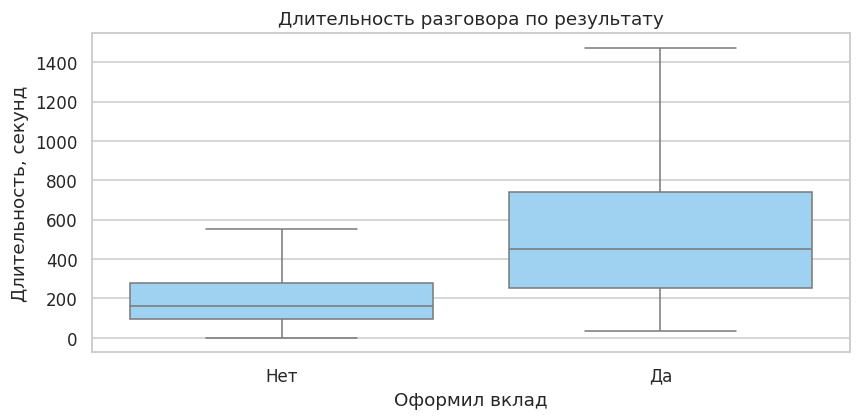

None

In [18]:
# Распределение длительности разговора по результату
print("Медианная длительность, секунд:")
display(df.groupby("y")["duration"].median().rename(index={"no": "Вклад не оформлен", "yes": "Вклад оформлен"}).to_frame("Медиана"))
fig, ax = plt.subplots(figsize=(8, 4))
sns.boxplot(data=df, x="y", y="duration", order=["no", "yes"], showfliers=False, color="#91D5FF", ax=ax)
ax.set_title("Длительность разговора по результату")
ax.set_xlabel("Оформил вклад")
ax.set_ylabel("Длительность, секунд")
ax.set_xticks([0, 1], labels=["Нет", "Да"])
plt.tight_layout()
plt.show()

Медианная длительность разговора составляет 164 секунды у `no` и 449 секунд у `yes`. Длительность заметно различается по итоговому ответу, но известна только после разговора. Поэтому график полезен для описания кампании, а `duration` нельзя использовать для выбора клиента до звонка: это создаст утечку информации.

In [19]:
# Число контактов до текущей кампании (previous)
previous_groups = pd.cut(
    df["previous"],
    bins=[-1, 0, 1, 2, float("inf")],
    labels=["0", "1", "2", "3+"],
)
previous_summary = df.assign(previous_group=previous_groups).groupby("previous_group", observed=False)["is_yes"].agg(
    contacts="size", deposits="sum", response_rate="mean"
)
previous_summary["response_rate_pct"] = (previous_summary["response_rate"] * 100).round(1)
display(previous_summary[["contacts", "deposits", "response_rate_pct"]].rename(columns={
    "contacts": "Контакты", "deposits": "Оформили вклад", "response_rate_pct": "Отклик, %"
}))

,Контакты,Оформили вклад,"Отклик, %"
previous_group,,,
0,35551,3140,8.8
1,4561,967,21.2
2,754,350,46.4
3+,310,182,58.7


None

Большинство клиентов не имели контактов, учтённых в `previous`. Доля отклика различается по числу прошлых контактов. Сопоставлять этот признак нужно вместе с `pdays` и `poutcome`: ранее обнаружено, что часть значений этих полей не согласуется.

,Контакты,Оформили вклад,"Отклик, %"
day_of_week,,,
Понедельник,8512,847,10.0
Вторник,8086,953,11.8
Среда,8134,949,11.7
Четверг,8618,1044,12.1
Пятница,7826,846,10.8


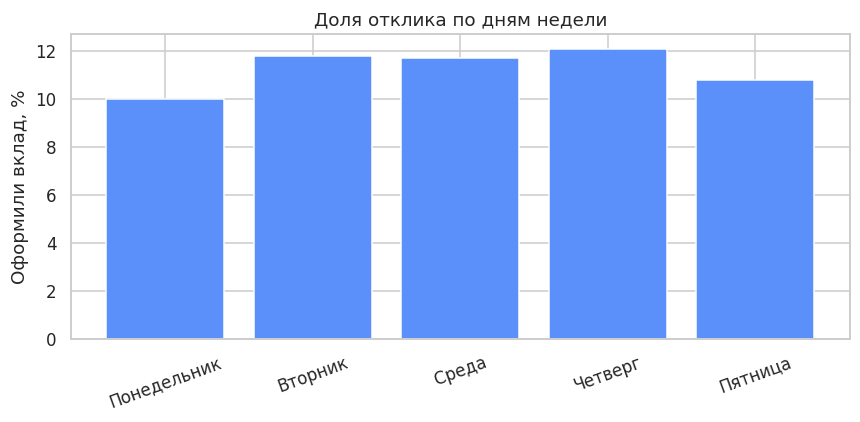

None

In [20]:
# Результаты по дням недели
weekday_names = {"mon": "Понедельник", "tue": "Вторник", "wed": "Среда", "thu": "Четверг", "fri": "Пятница"}
weekday_order = ["mon", "tue", "wed", "thu", "fri"]
weekday_summary = df.groupby("day_of_week")["is_yes"].agg(contacts="size", deposits="sum", response_rate="mean").reindex(weekday_order)
weekday_summary["response_rate_pct"] = (weekday_summary["response_rate"] * 100).round(1)
weekday_view = weekday_summary[["contacts", "deposits", "response_rate_pct"]].rename(index=weekday_names, columns={
    "contacts": "Контакты", "deposits": "Оформили вклад", "response_rate_pct": "Отклик, %"
})
display(weekday_view)
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(weekday_view.index, weekday_view["Отклик, %"], color="#5B8FF9")
ax.set_title("Доля отклика по дням недели")
ax.set_ylabel("Оформили вклад, %")
ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

Доля отклика по дням недели находится примерно в диапазоне 10–12%. В этой выборке четверг показывает наибольшую долю, понедельник — наименьшую. Разница невелика, поэтому день недели можно оставить кандидатом для модели, но его полезность нужно подтвердить при проверке модели.

# Анализ отклика клиентов на срочный вклад

В этом разделе мы сравниваем отклик по характеристикам клиентов, месяцам, способам связи и экономическим показателям. Цель — описать результаты кампании и выделить признаки, которые команда сможет проверить при построении модели.

Для основной части анализа использована таблица после удаления 12 полных дубликатов: 41 176 строк.

## 1. Портрет клиентов, оформивших вклад

Для каждой группы мы посчитали число контактов, число оформленных вкладов и долю отклика:

**число ответов `yes` / число всех контактов в группе × 100%.**

Также рассчитали долю вкладов группы среди всех оформленных вкладов. Это позволяет отличить группы с высоким процентом отклика от групп, которые дали наибольшее число вкладов.

In [21]:
category_names = {
    "job": {
        "admin.": "административный персонал", "blue-collar": "рабочие специальности",
        "entrepreneur": "предприниматели", "housemaid": "домашний персонал",
        "management": "управленцы", "retired": "пенсионеры",
        "self-employed": "самозанятые", "services": "сфера услуг",
        "student": "студенты", "technician": "технические специалисты",
        "unemployed": "безработные", "unknown": "неизвестно",
    },
    "marital": {"married": "в браке", "single": "не в браке", "divorced": "в разводе", "unknown": "неизвестно"},
    "education": {
        "basic.4y": "базовое образование, 4 года", "basic.6y": "базовое образование, 6 лет",
        "basic.9y": "базовое образование, 9 лет", "high.school": "среднее образование",
        "illiterate": "без образования", "professional.course": "профессиональное образование",
        "university.degree": "высшее образование", "unknown": "неизвестно",
    },
    "default": {"yes": "да", "no": "нет", "unknown": "неизвестно"},
    "housing": {"yes": "да", "no": "нет", "unknown": "неизвестно"},
    "loan": {"yes": "да", "no": "нет", "unknown": "неизвестно"},
}

def response_by_segment(data, column):
    result = (
        data.groupby(column, dropna=False, observed=True)["is_yes"]
        .agg(contacts="size", deposits="sum", response_rate="mean")
        .sort_values("response_rate", ascending=False)
    )
    result["response_rate_pct"] = (100 * result["response_rate"]).round(1)
    result["share_of_all_yes_pct"] = (100 * result["deposits"] / data["is_yes"].sum()).round(1)
    return result

profile_columns = ["age_group", "job", "marital", "education", "default", "housing", "loan"]
profile_labels = {
    "age_group": "Возраст", "job": "Профессия", "marital": "Семейное положение",
    "education": "Образование", "default": "Кредитная задолженность",
    "housing": "Жилищный кредит", "loan": "Личный кредит",
}
profile_tables = {}
for column in profile_columns:
    profile_tables[column] = response_by_segment(df, column)
    print(f"\nОтклик по полю «{profile_labels[column]}»")
    table = profile_tables[column][["contacts", "deposits", "response_rate_pct", "share_of_all_yes_pct"]].copy()
    table.index = [category_names.get(column, {}).get(str(value), str(value)) for value in table.index]
    table = table.rename(columns={
        "contacts": "Контакты", "deposits": "Оформили вклад",
        "response_rate_pct": "Отклик в группе, %",
        "share_of_all_yes_pct": "Доля от всех вкладов, %",
    })
    display(table)


Отклик по полю «Возраст»

Отклик по полю «Профессия»

Отклик по полю «Семейное положение»

Отклик по полю «Образование»

Отклик по полю «Кредитная задолженность»

Отклик по полю «Жилищный кредит»

Отклик по полю «Личный кредит»


,Контакты,Оформили вклад,"Отклик в группе, %","Доля от всех вкладов, %"
66+,618,290,46.9,6.3
до 25,1665,349,21.0,7.5
56–65,2963,451,15.2,9.7
26–35,14844,1740,11.7,37.5
46–55,8247,717,8.7,15.5
36–45,12839,1092,8.5,23.5


,Контакты,Оформили вклад,"Отклик в группе, %","Доля от всех вкладов, %"
студенты,875,275,31.4,5.9
пенсионеры,1718,434,25.3,9.4
безработные,1014,144,14.2,3.1
административный персонал,10419,1351,13.0,29.1
управленцы,2924,328,11.2,7.1
неизвестно,330,37,11.2,0.8
технические специалисты,6739,730,10.8,15.7
самозанятые,1421,149,10.5,3.2
домашний персонал,1060,106,10.0,2.3
предприниматели,1456,124,8.5,2.7


,Контакты,Оформили вклад,"Отклик в группе, %","Доля от всех вкладов, %"
неизвестно,80,12,15.0,0.3
не в браке,11564,1620,14.0,34.9
в разводе,4611,476,10.3,10.3
в браке,24921,2531,10.2,54.6


,Контакты,Оформили вклад,"Отклик в группе, %","Доля от всех вкладов, %"
без образования,18,4,22.2,0.1
неизвестно,1730,251,14.5,5.4
высшее образование,12164,1669,13.7,36.0
профессиональное образование,5240,595,11.4,12.8
среднее образование,9512,1031,10.8,22.2
"базовое образование, 4 года",4176,428,10.2,9.2
"базовое образование, 6 лет",2291,188,8.2,4.1
"базовое образование, 9 лет",6045,473,7.8,10.2


,Контакты,Оформили вклад,"Отклик в группе, %","Доля от всех вкладов, %"
нет,32577,4196,12.9,90.5
неизвестно,8596,443,5.2,9.5
да,3,0,0.0,0.0


,Контакты,Оформили вклад,"Отклик в группе, %","Доля от всех вкладов, %"
да,21571,2507,11.6,54.0
нет,18615,2025,10.9,43.7
неизвестно,990,107,10.8,2.3


,Контакты,Оформили вклад,"Отклик в группе, %","Доля от всех вкладов, %"
нет,33938,3849,11.3,83.0
да,6248,683,10.9,14.7
неизвестно,990,107,10.8,2.3


На графиках показана доля отклика внутри каждой группы. Размер группы можно посмотреть в таблице выше: это важно, потому что одинаковые проценты могут быть получены на разном количестве контактов.

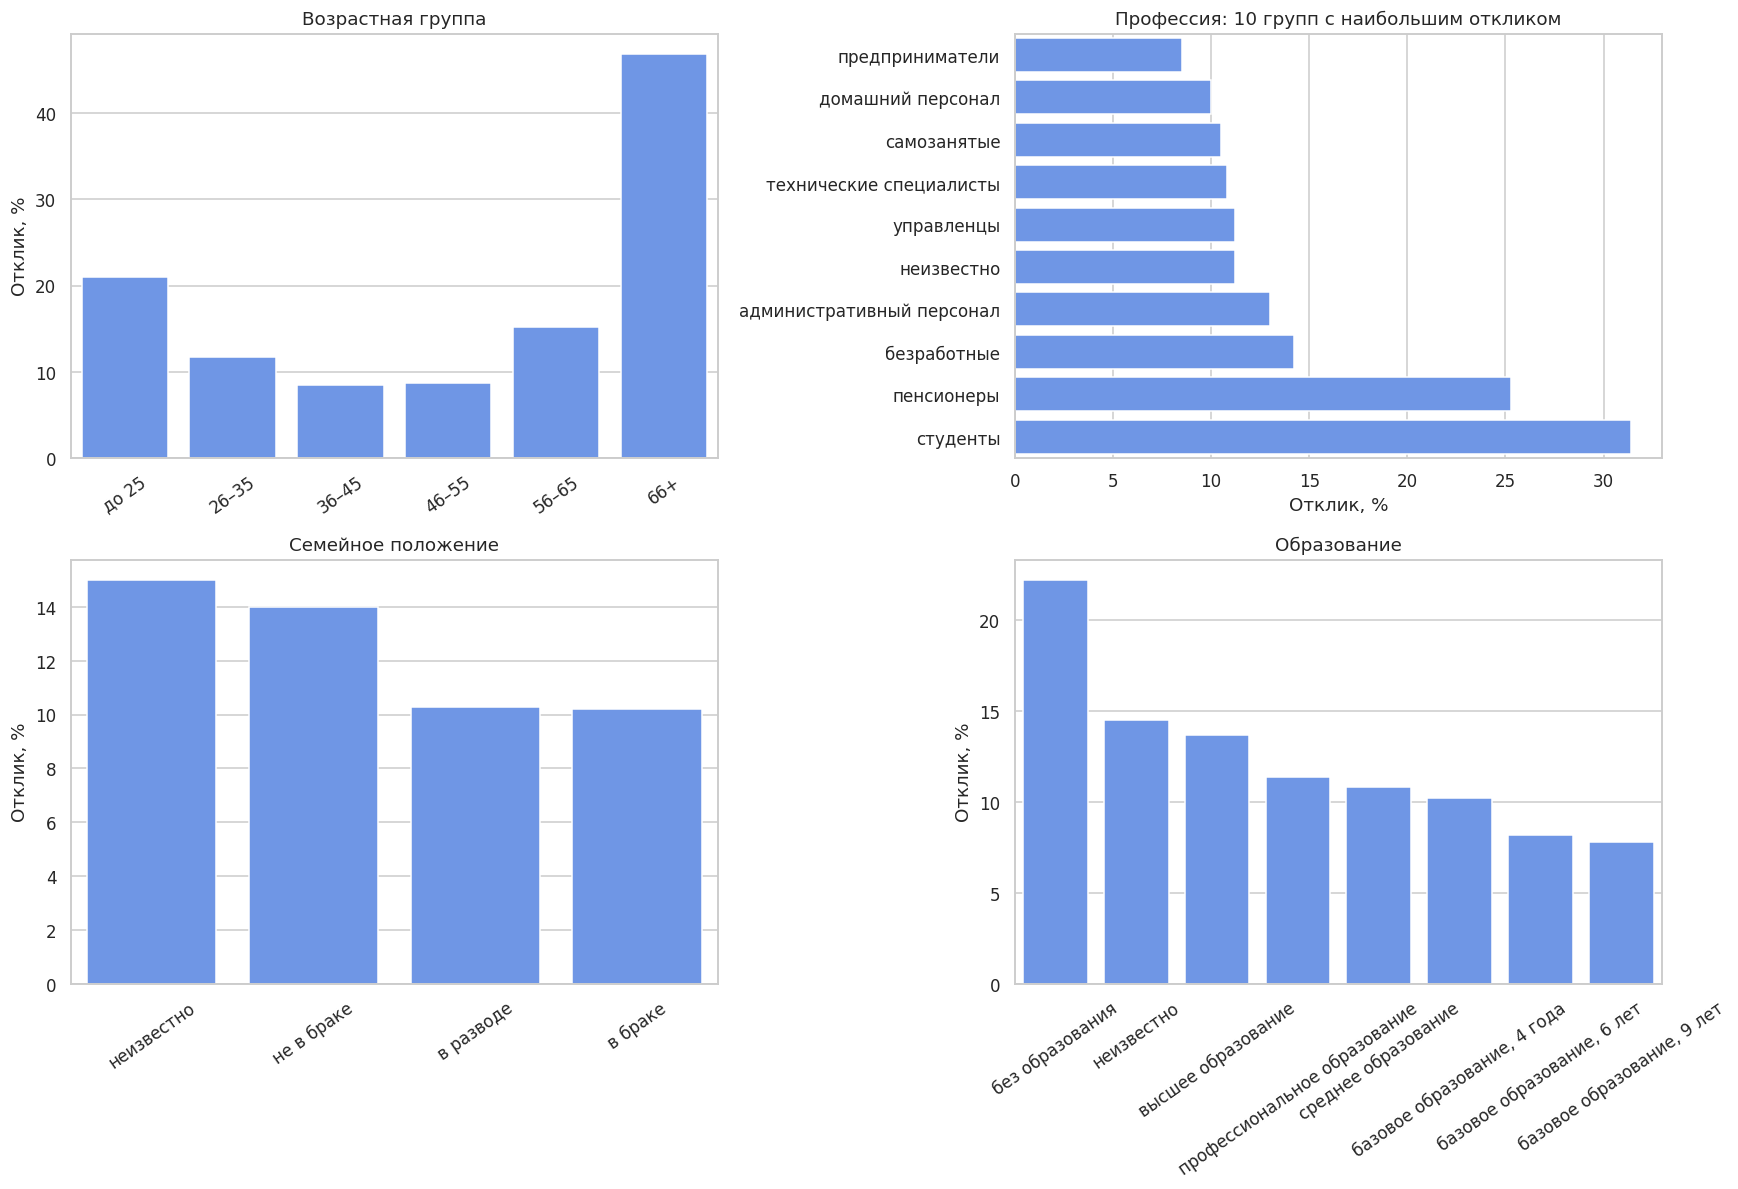

None

In [22]:
plot_columns = ["age_group", "job", "marital", "education"]
plot_titles = {
    "age_group": "Возрастная группа", "job": "Профессия: 10 групп с наибольшим откликом",
    "marital": "Семейное положение", "education": "Образование",
}
fig, axes = plt.subplots(2, 2, figsize=(16, 11))
for ax, column in zip(axes.flat, plot_columns):
    table = profile_tables[column].sort_values("response_rate_pct", ascending=False).reset_index()
    if column in category_names:
        table[column] = table[column].map(lambda value: category_names[column].get(str(value), str(value)))
    if column == "job":
        table = table.head(10).sort_values("response_rate_pct")
        sns.barplot(data=table, y=column, x="response_rate_pct", color="#5B8FF9", ax=ax)
        ax.set_xlabel("Отклик, %")
        ax.set_ylabel("")
    else:
        sns.barplot(data=table, x=column, y="response_rate_pct", color="#5B8FF9", ax=ax)
        ax.set_xlabel("")
        ax.set_ylabel("Отклик, %")
        ax.tick_params(axis="x", rotation=35)
    ax.set_title(plot_titles[column])
plt.tight_layout()
plt.show()


### Что получилось при сравнении групп

Самая высокая доля отклика по возрасту — у клиентов 66 лет и старше: 46,9% (290 из 618 контактов). Однако эта группа дала 6,3% всех вкладов. По профессии лидируют студенты — 31,4% (275 из 875), затем пенсионеры — 25,3% (434 из 1 718). Больше всего вкладов оформили клиенты 26–35 лет: 1 740, или 37,5% всех вкладов; доля отклика в этой группе — 11,7%.

Таким образом, для бизнес-портрета важны оба показателя: доля отклика и объём группы. Маленькие группы, например клиенты без образования, нужно трактовать осторожно. По жилищному кредиту доли отклика близки: 11,6% для категории `yes` и 10,9% для `no`. Для личного кредита значения также близки: 10,9% и 11,3%. В этой выборке эти признаки слабо различают результат кампании. Эти сравнения описывают выборку и не доказывают, что возраст или профессия вызывают отклик.

## 2. Результаты кампании по месяцам и каналам связи

Для каждого месяца и канала связи мы рассчитали число контактов, число оформленных вкладов и долю отклика. Процент показывает частоту отклика внутри группы, а абсолютное число вкладов — вклад группы в общий результат кампании.

In [23]:
month_names = {"mar": "Март", "apr": "Апрель", "may": "Май", "jun": "Июнь", "jul": "Июль", "aug": "Август", "sep": "Сентябрь", "oct": "Октябрь", "nov": "Ноябрь", "dec": "Декабрь"}
month_short = {"mar": "мар", "apr": "апр", "may": "май", "jun": "июн", "jul": "июл", "aug": "авг", "sep": "сен", "oct": "окт", "nov": "ноя", "dec": "дек"}
contact_names = {"cellular": "мобильная связь", "telephone": "телефон"}

monthly = (
    df.groupby("month", observed=False)["is_yes"]
    .agg(contacts="size", deposits="sum", response_rate="mean")
)
monthly["response_rate_pct"] = (100 * monthly["response_rate"]).round(1)
monthly["share_of_all_deposits_pct"] = (100 * monthly["deposits"] / df["is_yes"].sum()).round(1)
monthly_view = monthly.copy()
monthly_view.index = [month_names[str(month)] for month in monthly.index]
monthly_view = monthly_view.rename(columns={
    "contacts": "Контакты", "deposits": "Оформили вклад",
    "response_rate_pct": "Отклик, %",
    "share_of_all_deposits_pct": "Доля от всех вкладов, %",
})
print("Результаты по месяцам")
display(monthly_view[["Контакты", "Оформили вклад", "Отклик, %", "Доля от всех вкладов, %"]])

channel = (
    df.groupby("contact")["is_yes"]
    .agg(contacts="size", deposits="sum", response_rate="mean")
)
channel["response_rate_pct"] = (100 * channel["response_rate"]).round(1)
channel["share_of_all_deposits_pct"] = (100 * channel["deposits"] / df["is_yes"].sum()).round(1)
channel_view = channel.copy()
channel_view.index = [contact_names.get(str(value), str(value)) for value in channel.index]
channel_view = channel_view.rename(columns={
    "contacts": "Контакты", "deposits": "Оформили вклад",
    "response_rate_pct": "Отклик, %",
    "share_of_all_deposits_pct": "Доля от всех вкладов, %",
})
print("Результаты по каналам связи")
display(channel_view[["Контакты", "Оформили вклад", "Отклик, %", "Доля от всех вкладов, %"]])

Результаты по месяцам
Результаты по каналам связи


,Контакты,Оформили вклад,"Отклик, %","Доля от всех вкладов, %"
Март,546,276,50.5,5.9
Апрель,2631,539,20.5,11.6
Май,13767,886,6.4,19.1
Июнь,5318,559,10.5,12.1
Июль,7169,648,9.0,14.0
Август,6176,655,10.6,14.1
Сентябрь,570,256,44.9,5.5
Октябрь,717,315,43.9,6.8
Ноябрь,4100,416,10.1,9.0
Декабрь,182,89,48.9,1.9


,Контакты,Оформили вклад,"Отклик, %","Доля от всех вкладов, %"
мобильная связь,26135,3852,14.7,83.0
телефон,15041,787,5.2,17.0


None

Результат по каждому месяцу и каналу


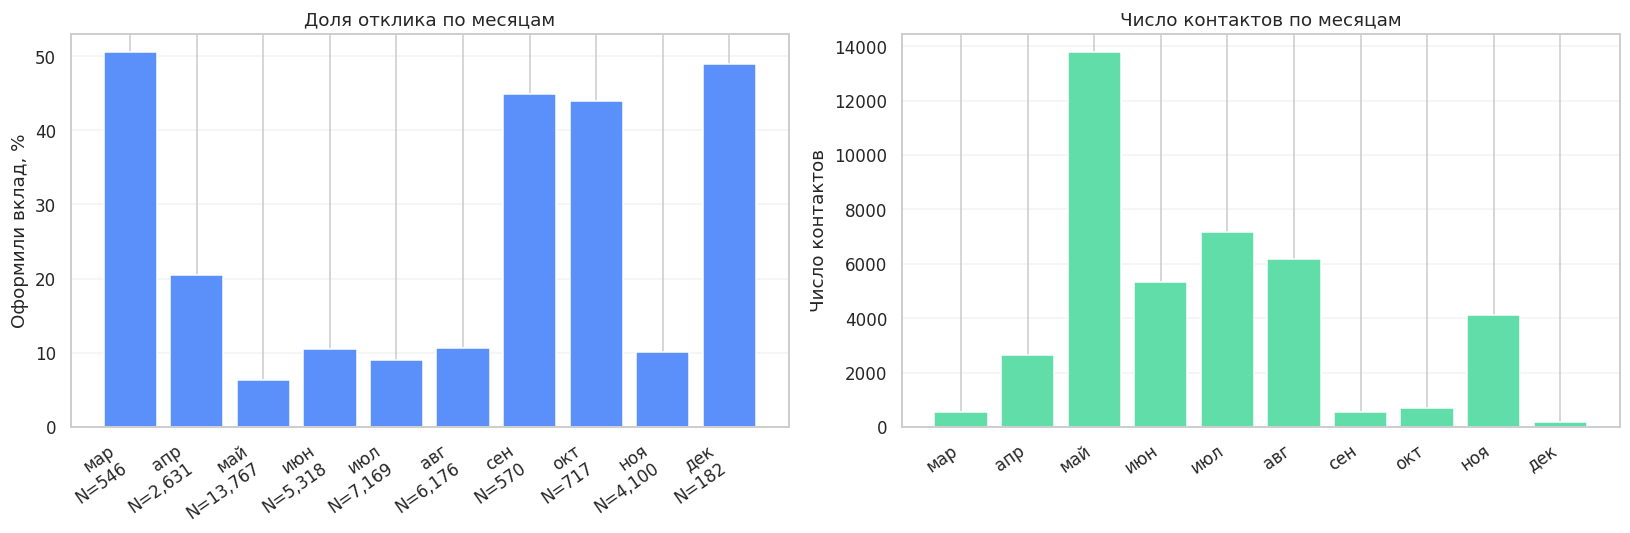

,Месяц,Канал связи,Контакты,Оформили вклад,"Отклик, %"
0,Март,мобильная связь,486,252,51.9
1,Март,телефон,60,24,40.0
2,Апрель,мобильная связь,2444,493,20.2
3,Апрель,телефон,187,46,24.6
4,Май,мобильная связь,5517,614,11.1
5,Май,телефон,8250,272,3.3
6,Июнь,мобильная связь,820,349,42.6
7,Июнь,телефон,4498,210,4.7
8,Июль,мобильная связь,6092,590,9.7
9,Июль,телефон,1077,58,5.4


None

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
month_labels = [f"{month_short[str(month)]}\nN={count:,}" for month, count in zip(monthly.index, monthly["contacts"])]
axes[0].bar(range(len(monthly)), monthly["response_rate_pct"], color="#5B8FF9")
axes[0].set_title("Доля отклика по месяцам")
axes[0].set_ylabel("Оформили вклад, %")
axes[0].set_xticks(range(len(monthly)), month_labels, rotation=35, ha="right")
axes[0].grid(axis="y", alpha=0.25)
axes[1].bar(range(len(monthly)), monthly["contacts"], color="#61DDAA")
axes[1].set_title("Число контактов по месяцам")
axes[1].set_ylabel("Число контактов")
axes[1].set_xticks(range(len(monthly)), [month_short[str(month)] for month in monthly.index], rotation=35, ha="right")
axes[1].grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

month_channel = (
    df.groupby(["month", "contact"], observed=True)["is_yes"]
    .agg(contacts="size", deposits="sum", response_rate="mean")
    .reset_index()
)
month_channel["response_rate_pct"] = (100 * month_channel["response_rate"]).round(1)
month_channel_view = month_channel[["month", "contact", "contacts", "deposits", "response_rate_pct"]].copy()
month_channel_view["month"] = month_channel_view["month"].astype(str).map(month_names)
month_channel_view["contact"] = month_channel_view["contact"].map(contact_names)
month_channel_view = month_channel_view.rename(columns={
    "month": "Месяц", "contact": "Канал связи", "contacts": "Контакты",
    "deposits": "Оформили вклад", "response_rate_pct": "Отклик, %",
})
print("Результат по каждому месяцу и каналу")
display(month_channel_view)

Таблица и график показывают два разных результата: долю отклика внутри месяца и общий объём контактов. Поэтому месяц с наибольшим процентом не обязательно даёт наибольшее число вкладов.

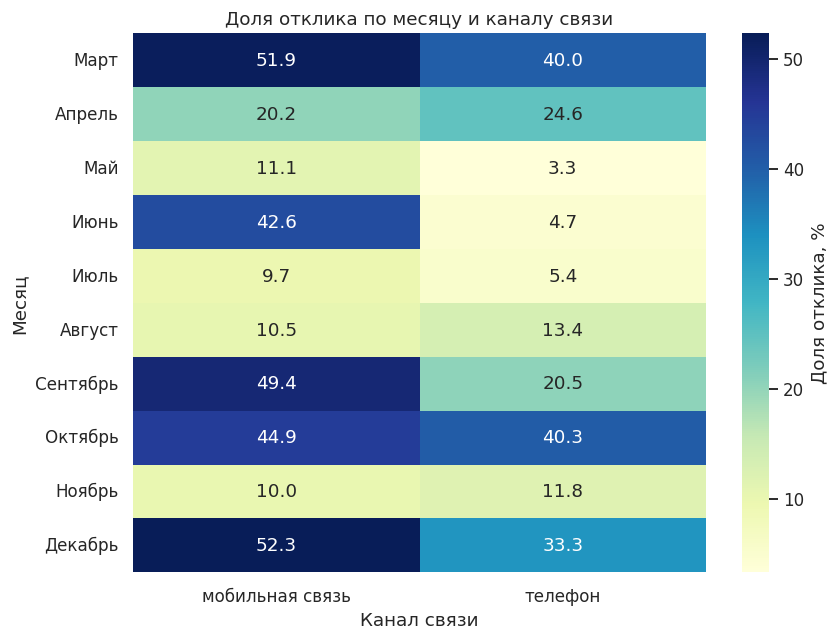

None

In [25]:
rate_matrix = month_channel.pivot(index="month", columns="contact", values="response_rate_pct").reindex(month_order)
rate_matrix.index = [month_names[str(month)] for month in rate_matrix.index]
rate_matrix = rate_matrix.rename(columns=contact_names)
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(rate_matrix, annot=True, fmt=".1f", cmap="YlGnBu", ax=ax, cbar_kws={"label": "Доля отклика, %"})
ax.set_title("Доля отклика по месяцу и каналу связи")
ax.set_xlabel("Канал связи")
ax.set_ylabel("Месяц")
plt.tight_layout()
plt.show()

Тепловая карта позволяет сравнить каналы внутри каждого месяца. В ячейках показана доля `yes`; при чтении нужно учитывать число контактов в соответствующей группе.

,Профессия,Канал,Контакты,Оформили вклад,"Отклик, %"
0,административный персонал,мобильная связь,7123,1158,16.3
1,административный персонал,телефон,3296,193,5.9
20,безработные,мобильная связь,620,123,19.8
21,безработные,телефон,394,21,5.3
6,домашний персонал,мобильная связь,640,83,13.0
7,домашний персонал,телефон,420,23,5.5
22,неизвестно,мобильная связь,168,26,15.5
23,неизвестно,телефон,162,11,6.8
10,пенсионеры,мобильная связь,1231,389,31.6
11,пенсионеры,телефон,487,45,9.2


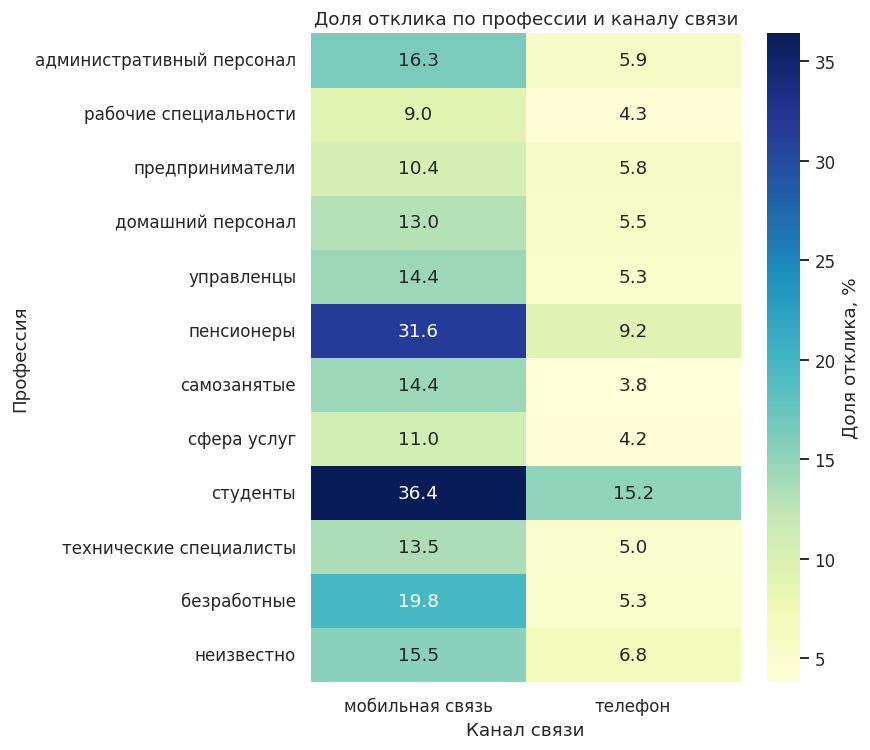

None

In [26]:
# Сравнение профессии и способа связи
job_contact = df.groupby(["job", "contact"], observed=True)["is_yes"].agg(
    contacts="size", deposits="sum", response_rate="mean"
).reset_index()
job_contact["response_rate_pct"] = (job_contact["response_rate"] * 100).round(1)
job_contact_view = job_contact[["job", "contact", "contacts", "deposits", "response_rate_pct"]].copy()
job_contact_view["job"] = job_contact_view["job"].map(lambda value: category_names["job"].get(value, value))
job_contact_view["contact"] = job_contact_view["contact"].map(contact_names)
job_contact_view = job_contact_view.rename(columns={
    "job": "Профессия", "contact": "Канал", "contacts": "Контакты",
    "deposits": "Оформили вклад", "response_rate_pct": "Отклик, %"
})
display(job_contact_view.sort_values(["Профессия", "Канал"]))

job_contact_matrix = job_contact.pivot(index="job", columns="contact", values="response_rate_pct")
job_contact_matrix.index = [category_names["job"].get(value, value) for value in job_contact_matrix.index]
job_contact_matrix = job_contact_matrix.rename(columns=contact_names)
fig, ax = plt.subplots(figsize=(8, 7))
sns.heatmap(job_contact_matrix, annot=True, fmt=".1f", cmap="YlGnBu", ax=ax, cbar_kws={"label": "Доля отклика, %"})
ax.set_title("Доля отклика по профессии и каналу связи")
ax.set_xlabel("Канал связи")
ax.set_ylabel("Профессия")
plt.tight_layout()
plt.show()

В большинстве профессиональных групп доля отклика при мобильной связи выше, чем при телефонной. При этом это сравнение не является экспериментом: в разные каналы могли попадать разные клиенты и кампании. Таблица полезна как дополнительная сегментация, а причинный эффект канала по ней установить нельзя.

### Что получилось по месяцам и каналам связи

После удаления полных дубликатов доля отклика составила около 14,7% при мобильной связи и 5,2% при телефонной. Это различие наблюдается в этой выборке, но не доказывает, что канал сам по себе повышает отклик: состав клиентов и условия контакта могли различаться.

В марте доля отклика была самой высокой — около 50,5%, при 546 контактах. В мае прошёл наибольший объём контактов — около 13,8 тыс.; там же оформлено больше всего вкладов среди месяцев. В наборе объединены несколько лет, а отдельной полной даты контакта нет, поэтому месячное различие следует рассматривать как описание исторических кампаний, а не как устойчивую сезонную закономерность.

## 3. Экономические показатели

Мы сравнили пять экономических показателей между ответами `yes` и `no`, посмотрели их медианы и взаимные корреляции. Медиана — середина упорядоченного ряда. Дополнительно рассмотрим долю отклика по диапазонам ставки Euribor: это помогает увидеть, как результат кампании распределялся при разных значениях показателя.

In [27]:
macro_columns = ["emp.var.rate", "cons.price.idx", "cons.conf.idx", "euribor3m", "nr.employed"]
macro_names = {
    "emp.var.rate": "Изменение занятости",
    "cons.price.idx": "Индекс потребительских цен",
    "cons.conf.idx": "Индекс уверенности потребителей",
    "euribor3m": "Ставка Euribor на 3 месяца",
    "nr.employed": "Число занятых",
}
macro_medians = df.groupby("y")[macro_columns].median().T
macro_medians["difference_yes_minus_no"] = macro_medians["yes"] - macro_medians["no"]
macro_medians = macro_medians.rename(columns={
    "no": "Медиана: вклад не оформили",
    "yes": "Медиана: вклад оформили",
    "difference_yes_minus_no": "Разница: yes минус no",
})
macro_medians.index = [macro_names[value] for value in macro_medians.index]
print("Медианы экономических показателей в двух группах")
display(macro_medians.round(3))

macro_corr = df[macro_columns].corr()
macro_corr_view = macro_corr.rename(index=macro_names, columns=macro_names)
print("Насколько экономические показатели менялись вместе")
display(macro_corr_view.round(2))

Медианы экономических показателей в двух группах
Насколько экономические показатели менялись вместе


y,Медиана: вклад не оформили,Медиана: вклад оформили,Разница: yes минус no
Изменение занятости,1.100,-1.800,-2.900
Индекс потребительских цен,93.918,93.200,-0.718
Индекс уверенности потребителей,-41.800,-40.400,1.400
Ставка Euribor на 3 месяца,4.857,1.266,-3.591
Число занятых,5195.800,5099.100,-96.700


,Изменение занятости,Индекс потребительских цен,Индекс уверенности потребителей,Ставка Euribor на 3 месяца,Число занятых
Изменение занятости,1.00,0.78,0.20,0.97,0.91
Индекс потребительских цен,0.78,1.00,0.06,0.69,0.52
Индекс уверенности потребителей,0.20,0.06,1.00,0.28,0.10
Ставка Euribor на 3 месяца,0.97,0.69,0.28,1.00,0.95
Число занятых,0.91,0.52,0.10,0.95,1.00


None

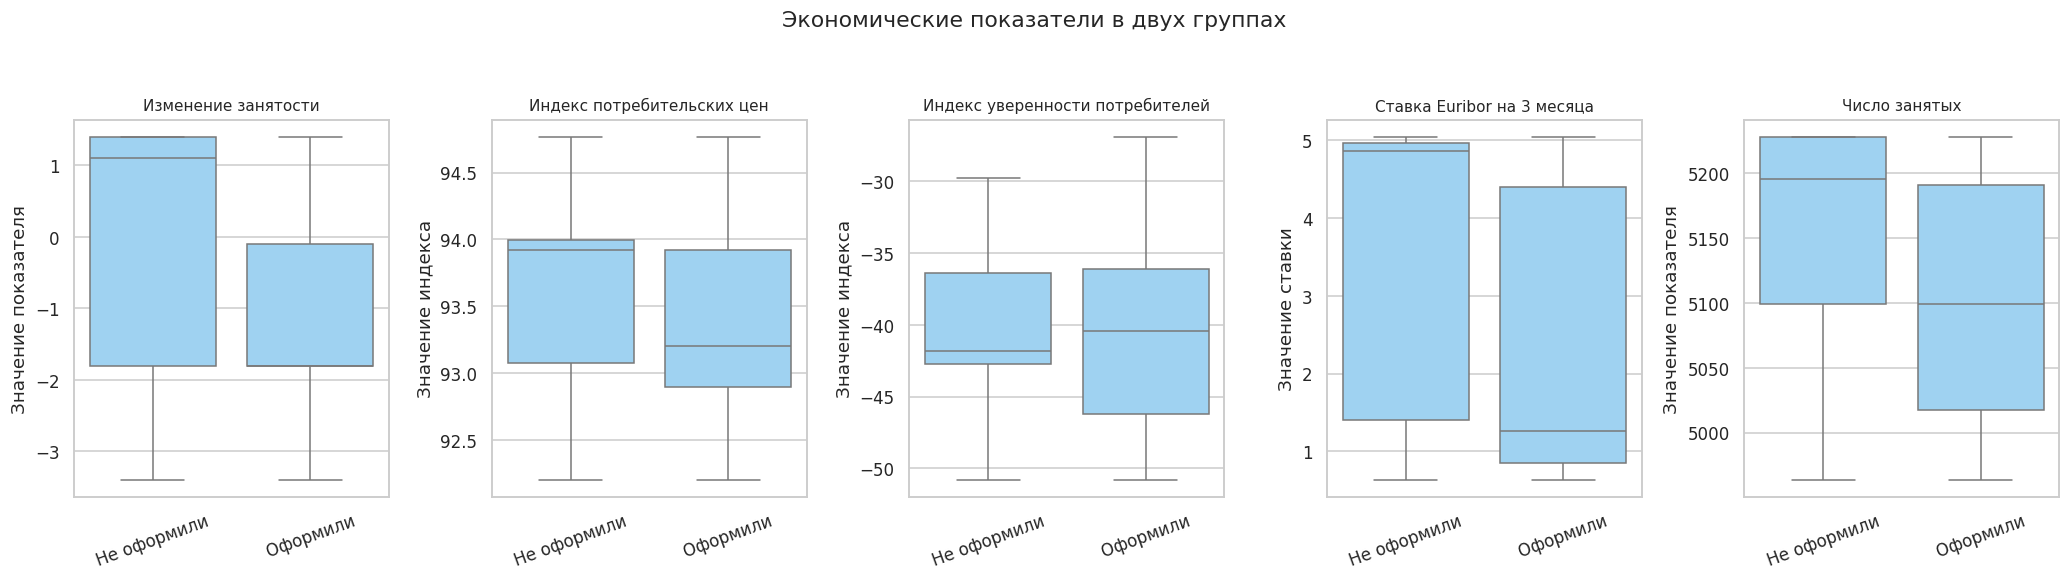

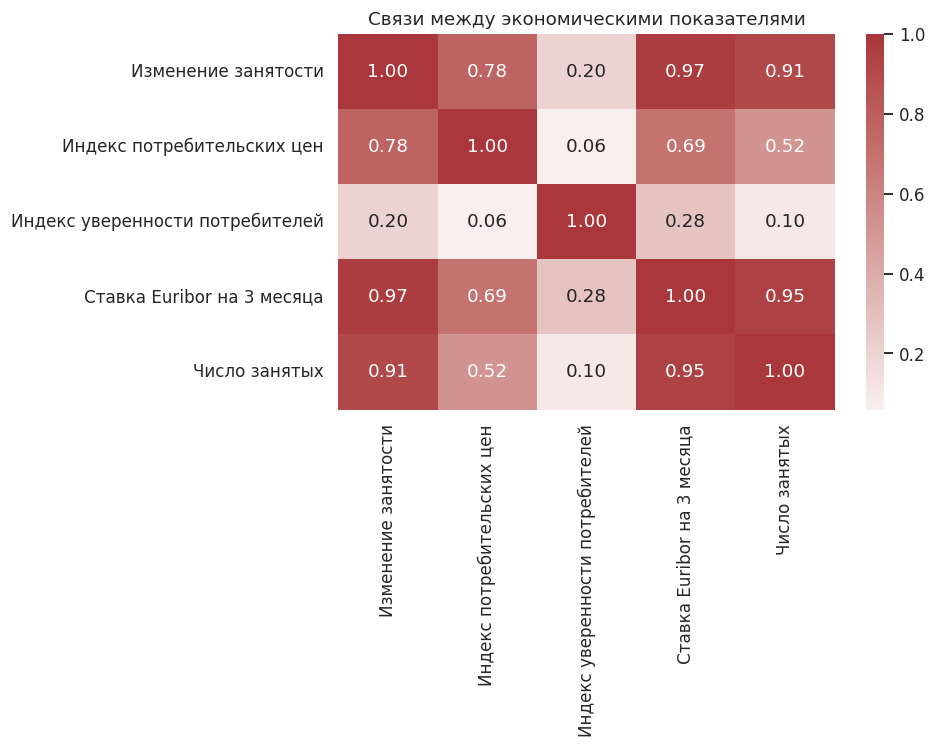

None

In [28]:
macro_units = {
    "emp.var.rate": "Значение показателя", "cons.price.idx": "Значение индекса",
    "cons.conf.idx": "Значение индекса", "euribor3m": "Значение ставки",
    "nr.employed": "Значение показателя",
}
fig, axes = plt.subplots(1, 5, figsize=(19, 5))
for ax, column in zip(axes, macro_columns):
    sns.boxplot(data=df, x="y", y=column, order=["no", "yes"], showfliers=False, ax=ax, color="#91D5FF")
    ax.set_title(macro_names[column], fontsize=10)
    ax.set_xlabel("")
    ax.set_xticks([0, 1], labels=["Не оформили", "Оформили"], rotation=20)
    ax.set_ylabel(macro_units[column])
plt.suptitle("Экономические показатели в двух группах", y=1.05)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(macro_corr_view, annot=True, fmt=".2f", cmap="vlag", center=0, ax=ax)
ax.set_title("Связи между экономическими показателями")
plt.tight_layout()
plt.show()

### Что видно по экономическим показателям

Медиана ставки Euribor составила 1,266 в группе `yes` и 4,857 в группе `no`. Медианное число занятых — 5 099,1 и 5 195,8 соответственно. Медиана изменения занятости — −1,8 у `yes` и 1,1 у `no`.

В этой выборке доля отклика различалась при разных экономических значениях. Эти показатели относятся к периоду контакта и не являются индивидуальными характеристиками клиента. Они могут отражать различия между периодами кампании, поэтому по одной медиане нельзя заключить, что именно экономическая ситуация вызвала отклик.

Изменение занятости и Euribor сильно коррелируют (около 0,97); корреляция Euribor с числом занятых — около 0,95. Это означает, что признаки часто менялись вместе. При построении модели стоит проверить, дают ли они дополнительную информацию по отдельности.

In [29]:
# Доля отклика в группах по ставке Euribor
# Квартильные группы позволяют сравнить диапазоны с близким числом контактов.
euribor_group = pd.qcut(df["euribor3m"], q=4, duplicates="drop")
euribor_summary = df.assign(euribor_group=euribor_group).groupby("euribor_group", observed=False)["is_yes"].agg(
    contacts="size", deposits="sum", response_rate="mean"
)
euribor_summary["response_rate_pct"] = (euribor_summary["response_rate"] * 100).round(1)
euribor_view = euribor_summary[["contacts", "deposits", "response_rate_pct"]].rename(columns={
    "contacts": "Контакты", "deposits": "Оформили вклад", "response_rate_pct": "Отклик, %"
})
display(euribor_view)
print("Число уникальных значений каждого макропоказателя:")
display(df[macro_columns].nunique().rename("Уникальные значения").to_frame())
print("Число уникальных сочетаний пяти показателей:", df[macro_columns].drop_duplicates().shape[0])

Число уникальных значений каждого макропоказателя:
Число уникальных сочетаний пяти показателей: 375


,Контакты,Оформили вклад,"Отклик, %"
euribor_group,,,
"(0.633, 1.344]",10540,2675,25.4
"(1.344, 4.857]",11509,950,8.3
"(4.857, 4.961]",9342,475,5.1
"(4.961, 5.045]",9785,539,5.5


,Уникальные значения
emp.var.rate,10
cons.price.idx,26
cons.conf.idx,26
euribor3m,316
nr.employed,11


None

В квартильных группах Euribor доля отклика выше при меньших значениях ставки. Это описание прошлых кампаний, а не доказательство влияния ставки: экономические признаки связаны с периодом, а часть макропоказателей сильно коррелирует. В модели стоит проверить, улучшают ли они прогноз на отложенной части данных и не дублируют ли информацию друг друга.

## 4. Признаки и проверки для следующего этапа

| Решение для модели | Признаки | Что проверить |
|---|---|---|
| Кандидаты | возраст, профессия, образование, планируемый канал, месяц контакта, история прошлых кампаний, экономические показатели | Доступны ли значения к моменту прогноза и улучшают ли качество модели на отложенной части данных |
| Использовать осторожно | `campaign`, `pdays`, `previous`, `poutcome`, экономические показатели | `campaign` может содержать будущие контакты; признаки истории частично противоречат друг другу; макропоказатели сильно коррелируют |
| Исключить для прогноза до звонка | `duration` | Становится известна только после разговора и приводит к утечке информации |

Значения `unknown` пока сохраняются как отдельные категории. Доля `yes` составляет 11,3%, поэтому качество модели нужно оценивать не только по общей точности: важны полнота, точность для класса `yes`, F1 и PR-AUC.

Ранжирование признаков по силе связи с `y` и проверку их вклада в прогноз лучше провести на обучающей части датасета вместе с ML-командой. В EDA мы сформировали кандидатов и указали риски доступности признаков.

## 5. Итог

В анализируемой части датасета осталось 41 176 контактов после удаления 12 полностью совпадающих строк; срочный вклад оформили 4 639 клиентов, или 11,3%. Наибольшая доля отклика среди рассмотренных возрастных групп была у клиентов 66 лет и старше, а наибольшее количество вкладов дали клиенты 26–35 лет. По профессии наиболее высокая доля отклика была у студентов. В этой выборке доля отклика при мобильной связи выше, чем при телефонной; по месяцам и экономическим показателям также наблюдались различия.

Эти результаты помогают описать прошедшие кампании и сформировать признаки для проверки в модели. До звонка могут быть доступны возраст, профессия и планируемый канал связи; доступность признаков истории контактов и экономических условий нужно проверить отдельно. Значения `campaign` могут включать контакты, которые произойдут позже момента прогноза, поэтому их нельзя брать без проверки. Для сценария прогноза до звонка `duration` использовать нельзя: длительность становится известна только после разговора. Полные дубли удалены до разделения данных, чтобы одинаковые строки не оказались одновременно в обучающей и проверочной выборках.

Следующий шаг команды — обучить модель и проверить её на отложенной части этого же датасета, сохранив порядок строк, поскольку данные упорядочены по времени. Так как ответ `yes` составляет 11,3%, качество важно оценивать не только по accuracy, но и по полноте, точности для `yes`, F1 и PR-AUC. Приведённые сравнения показывают связи в данных, но сами по себе не доказывают причин влияния на решение клиента.